In [21]:
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt
import ast
import seaborn as sns
#from adjustText import adjust_text

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x : ast.literal_eval(x) if pd.notna(x) else x)

In [23]:
df_DA_ind = df[(df['job_title_short'] == 'Data Analyst') & (df['job_country'] == 'India')].copy()
df_DA_ind = df_DA_ind.dropna(subset=['salary_year_avg'])

In [24]:
df_DA_ind = df_DA_ind.explode('job_skills')

In [27]:
df_DA_ind_group = df_DA_ind.groupby('job_skills')['salary_year_avg'].agg(['count', 'median'])

df_DA_toppay = df_DA_ind_group.sort_values(by = 'median', ascending=False).head(10)
df_DA_topskills = df_DA_ind_group.sort_values(by='count', ascending = False).sort_values(by='median').head(10)

(0.0, 160000.0)

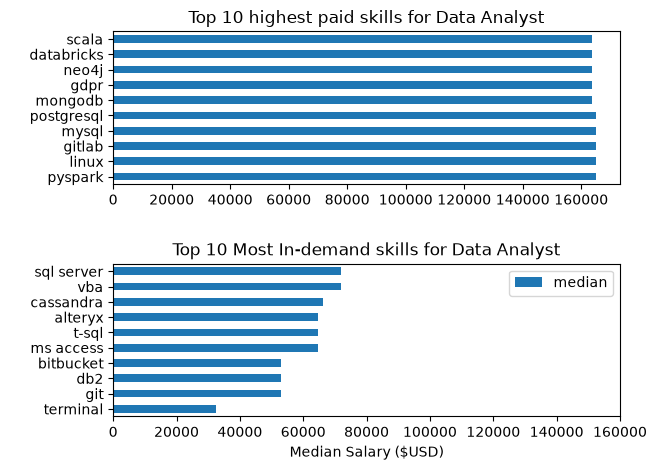

In [28]:
fig, ax= plt.subplots(2,1)

df_DA_toppay.plot(kind='barh', y='median', ax=ax[0], legend=False)
ax[0].set_title('Top 10 highest paid skills for Data Analyst')
ax[0].set_xlabel(' ')
ax[0].set_ylabel(' ')

df_DA_topskills.plot(kind='barh', y='median', ax=ax[1], legend=False)
ax[1].set_title('Top 10 Most In-demand skills for Data Analyst')
ax[1].set_xlabel('Median Salary ($USD)')
ax[1].set_ylabel(' ')
fig.tight_layout()
plt.legend()
plt.xlim(0,160000)